In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [ ]:
import os

# بررسی مسیر دانلود شده و پوشه‌های داخل آن
print("Dataset path:", path)
if os.path.exists(path):
    print("Contents of the dataset directory:")
    for item in os.listdir(path):
        item_path = os.path.join(path, item)
        if os.path.isdir(item_path):
            print(f" - [Directory] {item}: contains {len(os.listdir(item_path))} items/folders")
        else:
            print(f" - [File] {item}")
else:
    print("Path does not exist.")

Dataset path: /kaggle/input/chest-xray-pneumonia
Contents of the dataset directory:
 - [Directory] chest_xray: contains 5 items/folders


In [ ]:
inner_path = os.path.join(path, 'chest_xray')
print("Inner dataset path:", inner_path)
if os.path.exists(inner_path):
    for item in os.listdir(inner_path):
        item_path = os.path.join(inner_path, item)
        if os.path.isdir(item_path):
            print(f" - [Directory] {item}: contains {len(os.listdir(item_path))} subfolders/files")
        else:
            print(f" - [File] {item}")
else:
    print("Inner path does not exist.")

Inner dataset path: /kaggle/input/chest-xray-pneumonia/chest_xray
 - [Directory] chest_xray: contains 4 subfolders/files
 - [Directory] __MACOSX: contains 2 subfolders/files
 - [Directory] val: contains 2 subfolders/files
 - [Directory] test: contains 2 subfolders/files
 - [Directory] train: contains 2 subfolders/files


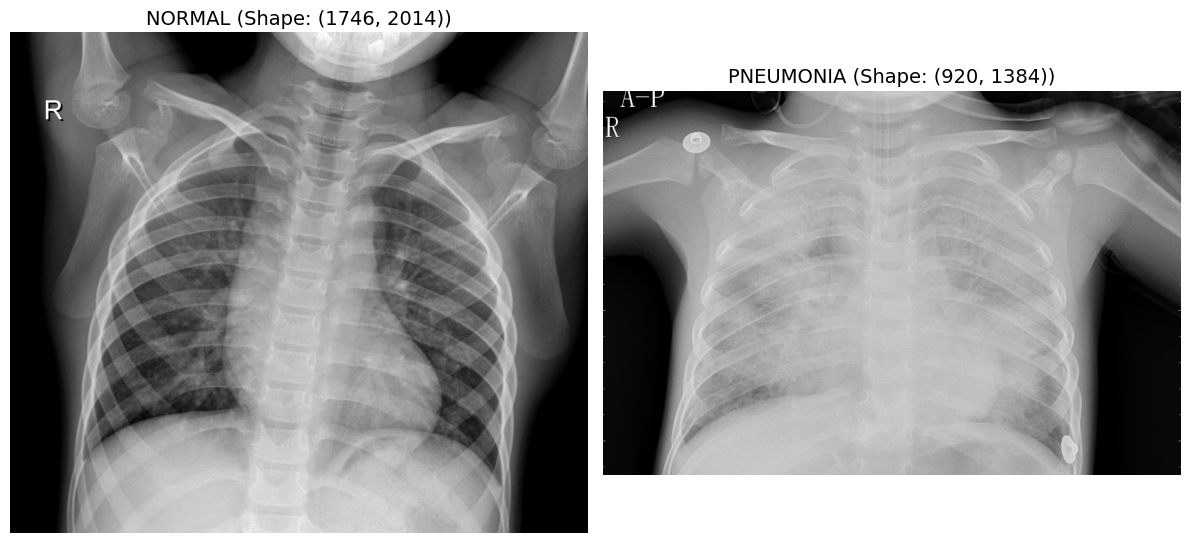

In [ ]:
import matplotlib.pyplot as plt
import cv2
import random

train_path = os.path.join(inner_path, 'train')
categories = ['NORMAL', 'PNEUMONIA']

plt.figure(figsize=(12, 6))

for i, category in enumerate(categories):
    category_path = os.path.join(train_path, category)
    images = os.listdir(category_path)
    random_image = random.choice(images)
    img_path = os.path.join(category_path, random_image)

    # Read and plot the image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.title(f"{category} (Shape: {img.shape[:2]})", fontsize=14)
    plt.axis('off')

plt.tight_layout()
plt.show()

,Split,Class,Count
0,train,NORMAL,1341
1,train,PNEUMONIA,3875
2,val,NORMAL,8
3,val,PNEUMONIA,8
4,test,NORMAL,234
5,test,PNEUMONIA,390


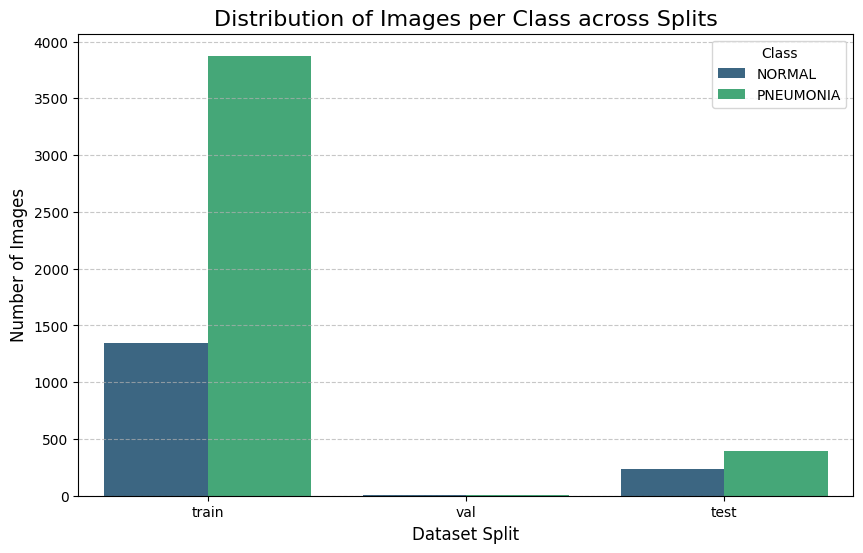

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# تعریف بخش‌های داده و کلاس‌ها
splits = ['train', 'val', 'test']
categories = ['NORMAL', 'PNEUMONIA']

data = []

for split in splits:
    for category in categories:
        folder_path = os.path.join(inner_path, split, category)
        if os.path.exists(folder_path):
            count = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])
            data.append({'Split': split, 'Class': category, 'Count': count})

# تبدیل اطلاعات به DataFrame
df_counts = pd.DataFrame(data)
display(df_counts)

# رسم نمودار توزیع کلاس‌ها
plt.figure(figsize=(10, 6))
sns.barplot(data=df_counts, x='Split', y='Count', hue='Class', palette='viridis')
plt.title('Distribution of Images per Class across Splits', fontsize=16)
plt.xlabel('Dataset Split', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ابعاد تصویر استاندارد برای مدل
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# تعریف ترانسفورم‌ها با افزودن قابلیت Augmentation برای داده‌های آموزش
train_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ترانسفورم ساده بدون تغییر خلاقانه برای مجموعه ارزیابی و تست
val_test_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ساخت مجموعه‌های داده با استفاده از ImageFolder
train_dataset = datasets.ImageFolder(root=os.path.join(inner_path, 'train'), transform=train_transforms)
val_dataset = datasets.ImageFolder(root=os.path.join(inner_path, 'val'), transform=val_test_transforms)
test_dataset = datasets.ImageFolder(root=os.path.join(inner_path, 'test'), transform=val_test_transforms)

# ساخت دیتالودرها
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# بررسی کلاس‌ها و تعداد داده‌های بارگذاری شده
print("Classes found:", train_dataset.classes)
print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Classes found: ['NORMAL', 'PNEUMONIA']
Train samples: 5216
Validation samples: 16
Test samples: 624


In [ ]:
# تست دیتالودر با کشیدن یک بچ نمونه
images, labels = next(iter(train_loader))
print(f"Images shape in batch: {images.shape}")
print(f"Labels shape in batch: {labels.shape}")

Images shape in batch: torch.Size([32, 3, 224, 224])
Labels shape in batch: torch.Size([32])


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# بررسی وضعیت سخت‌افزار (GPU یا CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# بارگذاری مدل پیش‌آموزش‌دیده ResNet18
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# فریز کردن لایه‌های استخراج ویژگی
for param in resnet_model.parameters():
    param.requires_grad = False

# تغییر لایه پایانی برای طبقه‌بندی دودویی (2 کلاس)
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 2)

# انتقال مدل به دستگاه محاسباتی
resnet_model = resnet_model.to(device)

# تعریف تابع خطا و بهینه‌ساز
criterion = nn.CrossEntropyLoss()
# فقط پارامترهای لایه جدید fc بهینه‌سازی می‌شوند
optimizer = optim.Adam(resnet_model.fc.parameters(), lr=0.001)

print(resnet_model)

Using device: cpu
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True,

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=5):
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        corrects = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_acc = corrects.double() / total

        # ارزیابی روی داده‌های ولیدیشن
        model.eval()
        val_loss = 0.0
        val_corrects = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_corrects += torch.sum(preds == labels.data)
                val_total += labels.size(0)

        val_epoch_loss = val_loss / val_total
        val_epoch_acc = val_corrects.double() / val_total

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} Acc: {val_epoch_acc:.4f}")

# آموزش اولیه مدل برای ۳ اپک به عنوان تست سریع
train_model(resnet_model, train_loader, val_loader, criterion, optimizer, epochs=3)

Epoch 1/3 | Train Loss: 0.2818 Acc: 0.8859 | Val Loss: 0.3273 Acc: 0.8125
Epoch 2/3 | Train Loss: 0.1873 Acc: 0.9275 | Val Loss: 0.3082 Acc: 0.7500
Epoch 3/3 | Train Loss: 0.1594 Acc: 0.9381 | Val Loss: 0.3505 Acc: 0.7500


Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.95      0.70      0.81       234
   PNEUMONIA       0.84      0.98      0.91       390

    accuracy                           0.87       624
   macro avg       0.90      0.84      0.86       624
weighted avg       0.88      0.87      0.87       624



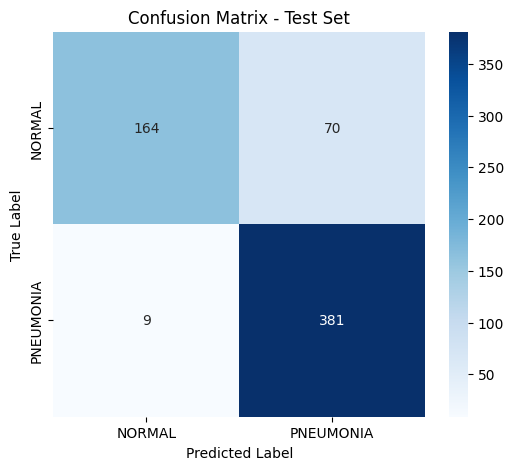

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

def evaluate_model(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    # Display Classification Report
    print("Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))

    # Plot Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=test_dataset.classes,
                yticklabels=test_dataset.classes)
    plt.title('Confusion Matrix - Test Set')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

# Run evaluation
evaluate_model(resnet_model, test_loader)

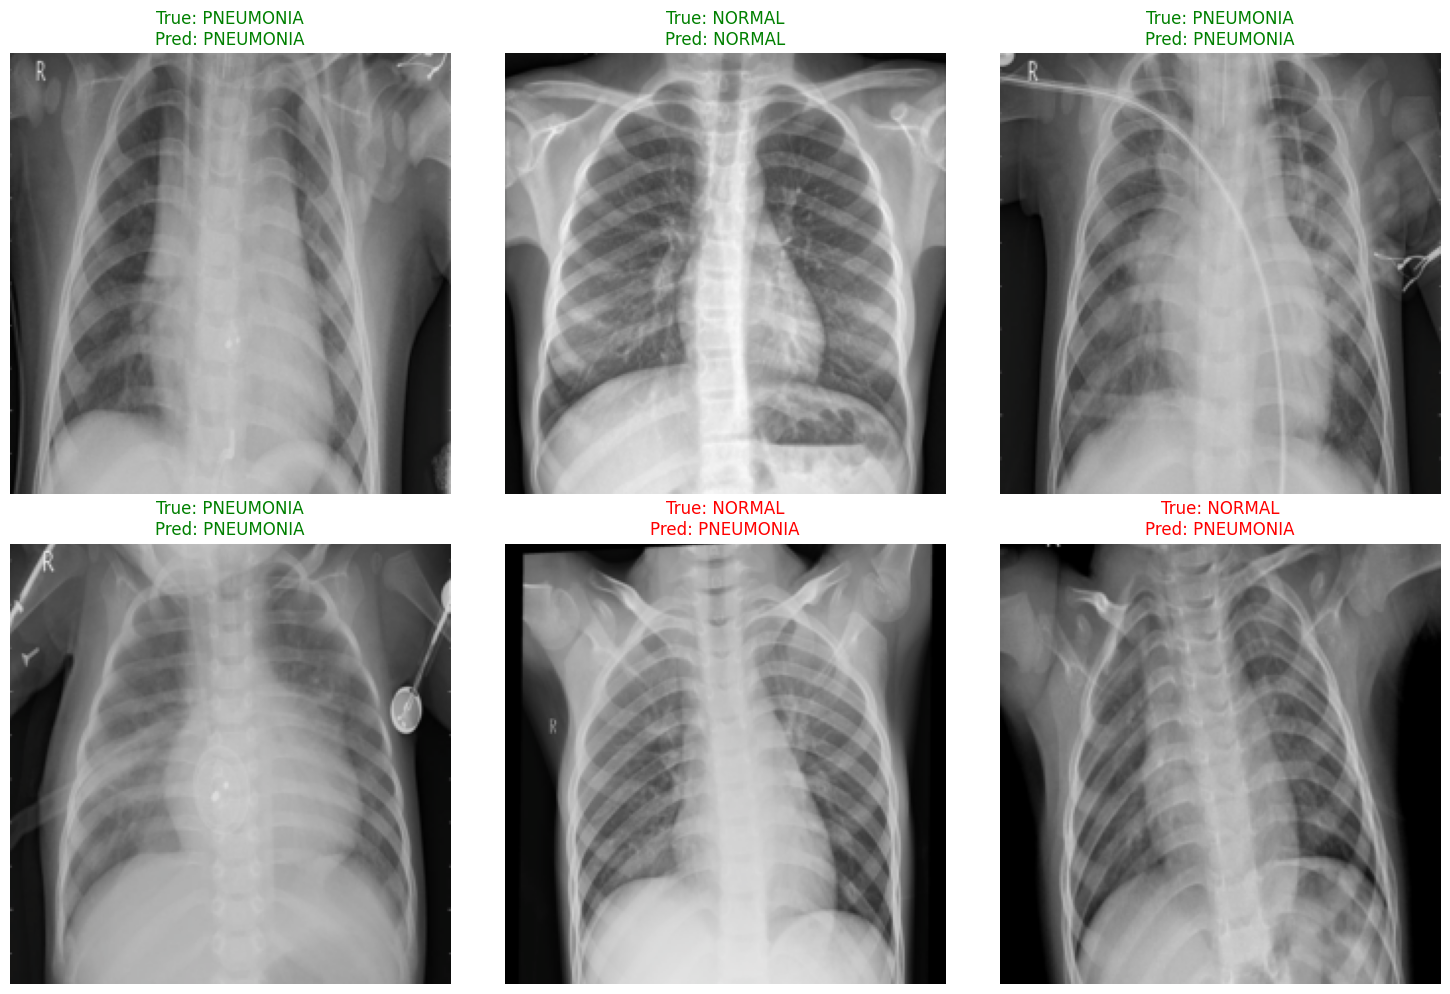

In [ ]:
import matplotlib.pyplot as plt
import random
import torch

# دریافت چند نمونه تصادفی از مجموعه تست برای نمایش پیش‌بینی‌ها
model = resnet_model
model.eval()

# انتخاب چند ایندکس تصادفی
total_test_images = len(test_dataset)
random_indices = random.sample(range(total_test_images), 6)

plt.figure(figsize=(15, 10))

# معکوس کردن نرمال‌سازی برای نمایش صحیح تصویر
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

with torch.no_grad():
    for i, idx in enumerate(random_indices):
        image, label = test_dataset[idx]

        # آماده‌سازی تصویر برای مدل
        input_tensor = image.unsqueeze(0).to(device)
        outputs = model(input_tensor)
        _, pred = torch.max(outputs, 1)

        # تبدیل مجدد تصویر به حالت قابل نمایش
        image_to_show = inv_normalize(image)
        image_to_show = image_to_show.permute(1, 2, 0).cpu().numpy()
        image_to_show = np.clip(image_to_show, 0, 1)

        true_class = test_dataset.classes[label]
        pred_class = test_dataset.classes[pred.item()]

        plt.subplot(2, 3, i + 1)
        plt.imshow(image_to_show)

        # تعیین رنگ عنوان بر اساس صحت پیش‌بینی
        color = 'green' if true_class == pred_class else 'red'
        plt.title(f"True: {true_class}\nPred: {pred_class}", color=color, fontsize=12)
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import torch

# Define the path to save the model weights
model_save_path = 'resnet18_pneumonia.pth'

# Save the state dictionary
torch.save(resnet_model.state_dict(), model_save_path)
print(f"Model successfully saved to {model_save_path}")

Model successfully saved to resnet18_pneumonia.pth


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# 1. Recreate the model architecture
loaded_model = models.resnet18()
num_ftrs = loaded_model.fc.in_features
loaded_model.fc = nn.Linear(num_ftrs, 2)

# 2. Load the saved weights
loaded_model.load_state_dict(torch.load('resnet18_pneumonia.pth', map_location=device))
loaded_model = loaded_model.to(device)
loaded_model.eval()

print("Model architecture recreated and weights loaded successfully.")

Model architecture recreated and weights loaded successfully.


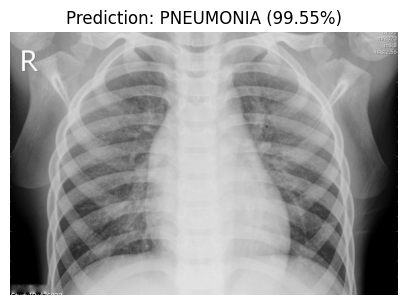

('PNEUMONIA', 99.55193996429443)

In [ ]:
import cv2
from PIL import Image
import matplotlib.pyplot as plt

def predict_image(image_path, model, transform, classes):
    # Load and preprocess the image
    image = Image.open(image_path).convert('RGB')
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Perform inference
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, pred_class_idx = torch.max(probabilities, 1)

    predicted_class = classes[pred_class_idx.item()]
    conf_score = confidence.item() * 100

    # Display the result
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(f"Prediction: {predicted_class} ({conf_score:.2f}%)")
    plt.axis('off')
    plt.show()

    return predicted_class, conf_score

# Let's test it with a sample image from the test set
sample_test_image_path = os.path.join(inner_path, 'test', 'PNEUMONIA', os.listdir(os.path.join(inner_path, 'test', 'PNEUMONIA'))[0])
predict_image(sample_test_image_path, loaded_model, val_test_transforms, test_dataset.classes)